# 14 · Segments x risk -> deposit policy

**Tasks:** P6-01 to P6-06 and P7-09 · **Owner:** M1 · Mahdhi S.M.M (IT24100667)

**Goal:** Decide **which bookings the hotel should ask for a deposit**. We use two finished tools:
- the **risk score** from the final classifier (XGBoost, `10a_model_gradient_boosting`, M4): the chance that a booking cancels
- the **segment** from `12_clustering` (M1): what kind of booking it is

## Summary



| Item | Result |
|---|---|
| **Final rule** | **Ask for a deposit if risk ≥ 0.35** (the same for all 3 segments) |
| Why 0.35 | Highest net money on train + val (Step 3). It is close to the break-even risk 0.33. |
| Why one rule for all segments | No segment earned 5% more with its own threshold (best gain: 1.4%, Step 4) |
| Assumptions | deposit = 20% of booking value · 10% of asked good guests leave |

**On the test set (used once):**

| | All | Short solo stays | Short stays for two | Long planned holidays |
|---|---|---|---|---|
| Asked for a deposit | 43.4% | 19.6% | 41.6% | 50.4% |
| Precision | 0.520 | 0.465 | 0.484 | 0.549 |
| Recall | 0.662 | 0.451 | 0.626 | 0.713 |

**Estimated money on test:** deposits protect **542,218** (14.5% of the value of all cancelled bookings). Cost: **3,575** good guests asked. **Estimated net: +326,278.**

## The idea

The rule is: **ask for a deposit if risk ≥ threshold.** This notebook chooses the threshold.

We choose it with **money**. When we ask a **canceller**, the hotel keeps a deposit of **20%** of the booking value. When we ask a **good guest**, there is a **10%** chance they leave, so we lose 10% of their value on average.

| Booking | Risk | Really cancelled? | Booking value |
|---|---|---|---|
| A | 0.80 | Yes | 600 |
| B | 0.55 | Yes | 600 |
| C | 0.45 | No | 600 |
| D | 0.70 | Yes | 200 |
| E | 0.20 | No | 200 |

- **Threshold 0.6:** we ask A and D. Deposits kept: 120 + 40 = **net +160**. But we missed canceller B.
- **Threshold 0.4:** we ask A, B, C and D. Deposits kept: 120 + 120 + 40 = +280. Good guest C asked: −60. **Net +220.** Better.

**The best threshold is the one with the highest net money.**


## Setup

**What we do:** Import the libraries, set the paths and write our assumptions in one place.

**Why:** The data does not say how big a deposit is, or how many guests leave when asked. **So we choose these values and write them down clearly.**

| Assumption | Value | Why |
|---|---|---|
| Deposit size | **20%** of the booking value | Many hotels ask for about one night or a small part of the stay |
| Good guests who leave when asked | **10%** | No data exists; most guests accept a deposit, some do not |
| A segment gets its own threshold | only if it earns **5% more** | A small gain can be luck; one threshold is simpler for staff |
| Thresholds we try | **0.30 to 0.70**, steps of 0.05 | Below 0.30 we ask too many guests; above 0.70 we catch very few cancellers |

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

# Hide library notices (for example "this option will change in a future version").
# They do not change any result.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42      # team rule: 42 everywhere

DEPOSIT_RATE = 0.20    # the hotel keeps 20% of the booking value when a canceller was asked
WALKAWAY_RATE = 0.10   # 10% of good guests who are asked go to another hotel
MIN_GAIN = 0.05        # a segment needs 5% more money to get its own threshold
THRESHOLDS = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

In [ ]:
# Find the project folder (works from the project folder or from notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed" / "shared_prepared"
SEGMENT_DIR = ROOT / "data" / "processed" / "clusters"
XGB_FILE = ROOT / "models" / "xgb_final" / "xgb_hotel_cancellation_pipeline.joblib"
CLUSTER_FILE = ROOT / "models" / "clustering_kmeans.joblib"
OUT_DIR = ROOT / "data" / "processed" / "policy"

## Step 1 · Honest risk scores for train + val

**What we do:**
1. Load train, val and test. Join train and val into `train_final`, because the final XGBoost (notebook 10a) learned from train + val.
2. Make the extra features that notebook 10a makes before its Pipeline (code copied from notebook 10a, M4).
3. Give every train + val booking a risk score with **out-of-fold** cross-validation (the shared 5 folds).

**Why:** We choose the threshold with these scores. **The scores must look like scores for new bookings.**


In [ ]:
train = pd.read_csv(DATA_DIR / "hotel_train_prepared.csv")
val = pd.read_csv(DATA_DIR / "hotel_val_prepared.csv")
test = pd.read_csv(DATA_DIR / "hotel_test_prepared.csv")

train_final = pd.concat([train, val], ignore_index=True)  # same data as notebook 10a
print("train_final:", train_final.shape, "| test:", test.shape)

train_final: (68650, 29) | test: (17324, 29)


In [ ]:
# ---- Copied from notebook 10a (M4): extra features made before the Pipeline ----

def create_arrival_date(df):
    df = df.copy()
    df[["agent", "company"]] = df[["agent", "company"]].astype(str)
    df["arrival_date_month_num"] = pd.to_datetime(df["arrival_date_month"], format="%B").dt.month
    df["arrival_date"] = pd.to_datetime(dict(
        year=df["arrival_date_year"],
        month=df["arrival_date_month_num"],
        day=df["arrival_date_day_of_month"],
    ))
    df["booking_date"] = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
    df["days_since_arrival"] = (df["arrival_date"].max() - df["arrival_date"]).dt.days
    return df


def add_features(df, adr_ref):
    df = df.copy()
    df["booking_month"] = df["booking_date"].dt.month
    df["booking_dow"] = df["booking_date"].dt.dayofweek
    n_prev = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
    df["prev_cancel_ratio"] = df["previous_cancellations"] / (n_prev + 1)
    df["adr_per_guest"] = df["adr"] / df["total_guests"].clip(lower=1)
    df["weekend_share"] = df["stays_in_weekend_nights"] / df["total_nights"].clip(lower=1)
    df["lead_per_night"] = df["lead_time"] / df["total_nights"].clip(lower=1)
    df = df.join(adr_ref, on=["hotel", "reserved_room_type", "arrival_date_month"])
    df["adr_ratio"] = df["adr"] / df["adr_ref"].replace(0, np.nan)
    return df.drop(columns="adr_ref")

# ---- End of copied code ----

In [ ]:
# Make the extra features (reference prices come from train_final only, like notebook 10a)
train_final_x = create_arrival_date(train_final)
test_x = create_arrival_date(test)

adr_ref = train_final_x.groupby(["hotel", "reserved_room_type", "arrival_date_month"])["adr"].median()
adr_ref = adr_ref.rename("adr_ref")

X_train_final = add_features(train_final_x, adr_ref).drop(columns=["is_canceled"])
y_train_final = train_final["is_canceled"]
X_test = add_features(test_x, adr_ref).drop(columns=["is_canceled"])

In [ ]:
# M4's final Pipeline (notebook 10a). cross_val_predict trains a fresh copy for each fold.
xgb_pipeline = joblib.load(XGB_FILE)

# Same sample weights as notebook 10a: newer bookings count more (half-life 180 days)
age_in_days = (X_train_final["arrival_date"].max() - X_train_final["arrival_date"]).dt.days
sample_weights = 0.5 ** (age_in_days / 180)

# The shared folds (team rule)
shared_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_proba = cross_val_predict(
    xgb_pipeline,
    X_train_final,
    y_train_final,
    cv=shared_folds,
    method="predict_proba",
    params={"xgb__sample_weight": sample_weights.to_numpy()},
)
train_final["risk"] = oof_proba[:, 1]  # column 1 = chance of "cancelled"

print("Out-of-fold ROC-AUC:", round(roc_auc_score(y_train_final, train_final["risk"]), 4))

Out-of-fold ROC-AUC: 0.789


**What we found:** Every train + val booking (68,650) has a risk score from a model that did not see it. The out-of-fold ROC-AUC is **0.789**. This is a little higher than M4's validation score (0.776) and the test score (0.738, Step 5). Our interpretation: the shuffled folds mix booking dates, so **these scores are a little optimistic for future bookings**.

## Step 2 · Segment x risk table (P6-01)

**What we do:**
1. Join each booking with its segment from notebook 12, using `booking_id`.
2. Booking value = `adr` × `total_nights` (with the same `adr` maximum as notebook 12).
3. Keep only **"No Deposit"** bookings. Bookings that already have a deposit cannot be asked again.
4. One table per segment: share of bookings, real cancel rate, average risk, average value, and **value at risk** (the value of the bookings that really cancelled).

**Why:** **If the model works, the average risk of each segment should be close to its real cancel rate.** The table also shows where the money is lost.

In [ ]:
# Segments from notebook 12
segments = pd.concat([
    pd.read_csv(SEGMENT_DIR / "segments_train.csv"),
    pd.read_csv(SEGMENT_DIR / "segments_val.csv"),
], ignore_index=True)
data = train_final.merge(segments, on="booking_id", how="left")
print("Bookings without a segment:", data["segment"].isna().sum())

# Booking value, with the same adr maximum as notebook 12
clustering = joblib.load(CLUSTER_FILE)
adr_max = clustering["adr_max"]
data["booking_value"] = data["adr"].clip(lower=0, upper=adr_max) * data["total_nights"]

# Only "No Deposit" bookings
print(data["deposit_type"].value_counts())
policy_data = data[data["deposit_type"] == "No Deposit"].copy()
print("Bookings for the deposit rule:", len(policy_data), "of", len(data))

Bookings without a segment: 0
deposit_type
No Deposit    67701
Non Refund      860
Refundable       89
Name: count, dtype: int64
Bookings for the deposit rule: 67701 of 68650


In [ ]:
# Money lost = booking value, only for bookings that really cancelled
policy_data["lost_value"] = policy_data["booking_value"] * policy_data["is_canceled"]

segment_table = policy_data.groupby(["segment", "segment_name"]).agg(
    bookings=("booking_id", "count"),
    real_cancel_rate_pct=("is_canceled", "mean"),
    average_risk_pct=("risk", "mean"),
    average_value=("booking_value", "mean"),
    value_at_risk=("lost_value", "sum"),
)
segment_table["real_cancel_rate_pct"] = segment_table["real_cancel_rate_pct"] * 100
segment_table["average_risk_pct"] = segment_table["average_risk_pct"] * 100
segment_table["share_of_bookings_%"] = segment_table["bookings"] / len(policy_data) * 100
segment_table["share_of_value_at_risk_%"] = segment_table["value_at_risk"] / segment_table["value_at_risk"].sum() * 100

segment_table.round(1)

,,bookings,real_cancel_rate_pct,average_risk_pct,average_value,value_at_risk,share_of_bookings_%,share_of_value_at_risk_%
segment,segment_name,,,,,,,
1,Short solo stays,12539,16.1,16.900000,174.0,439566.3,18.5,6.0
2,Short stays for two,29517,24.2,24.799999,236.0,1876062.0,43.6,25.5
3,Long planned holidays,25645,30.6,31.400000,588.1,5054956.2,37.9,68.6


**What we found:** 

- All bookings found their segment (0 missing). **949** bookings already have a deposit, so **67,701 (98.6%)** are in the deposit rule.
- **The average risk is within 1 point of the real cancel rate in every segment** (16.9% vs 16.1%, 24.8% vs 24.2%, 31.4% vs 30.6%). So the risk scores match the real rates well.
- **Long planned holidays are 37.9% of bookings, but 68.6% of the value at risk.** Their average value is 588.1, compared with 174.0 and 236.0.

## Step 3 · Choose the threshold (P6-02)

**What we do:** For every threshold from 0.30 to 0.70, we count TP, FP, FN, TN and calculate:
- **money kept** = 20% of the value of every canceller we asked (TP)
- **money lost** = 10% of the value of every good guest we asked (FP)
- **net money** = money kept − money lost

We choose the threshold with the **highest net money**.

**Why:** **The hotel cares about money, not about one score.** Accuracy and F1 treat both mistakes as equally bad, but a missed canceller (an empty room) costs more than an annoyed guest.

In [ ]:
def check_threshold(df, threshold):
    # threshold can be one number, or one number per booking
    asked = df["risk"] >= threshold
    cancelled = df["is_canceled"] == 1

    tp = (asked & cancelled).sum()     # canceller, asked
    fp = (asked & ~cancelled).sum()    # good guest, asked
    fn = (~asked & cancelled).sum()    # canceller, not asked
    tn = (~asked & ~cancelled).sum()   # good guest, not asked

    money_kept = DEPOSIT_RATE * df.loc[asked & cancelled, "booking_value"].sum()
    money_lost = WALKAWAY_RATE * df.loc[asked & ~cancelled, "booking_value"].sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    return {
        "asked_%": asked.mean() * 100,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "money_kept": money_kept,
        "money_lost": money_lost,
        "net_money": money_kept - money_lost,
    }

In [ ]:
rows = []
for t in THRESHOLDS:
    row = check_threshold(policy_data, t)
    row["threshold"] = t
    rows.append(row)
threshold_table = pd.DataFrame(rows).set_index("threshold")

# The threshold with the highest net money
best_threshold = threshold_table["net_money"].idxmax()
print("Best threshold:", best_threshold)

threshold_table.round(3)

Best threshold: 0.35


,asked_%,TP,FP,FN,TN,precision,recall,F1,money_kept,money_lost,net_money
threshold,,,,,,,,,,,
0.30,37.674,11859,13647,5168,37027,0.465,0.696,0.558,1126439.015,594131.295,532307.720
0.35,32.008,10630,11040,6397,39634,0.491,0.624,0.549,1035827.836,494704.212,541123.624
0.40,25.096,8920,8070,8107,42604,0.525,0.524,0.524,904701.192,380264.943,524436.250
0.45,18.054,6872,5351,10155,45323,0.562,0.404,0.470,736246.283,268500.636,467745.646
0.50,12.071,5042,3130,11985,47544,0.617,0.296,0.400,568363.251,167594.034,400769.217
0.55,7.691,3517,1690,13510,48984,0.675,0.207,0.316,409637.425,94986.540,314650.886
0.60,4.783,2412,826,14615,49848,0.745,0.142,0.238,287148.023,46061.783,241086.240
0.65,3.056,1708,361,15319,50313,0.826,0.100,0.179,206213.104,20478.184,185734.920
0.70,2.081,1261,148,15766,50526,0.895,0.074,0.137,152766.045,9199.509,143566.537


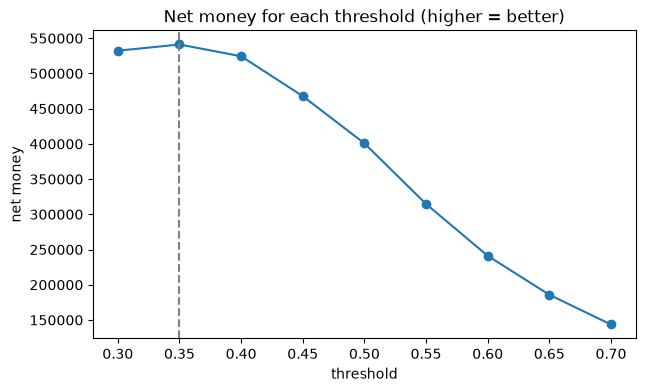

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(threshold_table.index, threshold_table["net_money"], marker="o")
plt.axvline(best_threshold, color="grey", linestyle="--")
plt.title("Net money for each threshold (higher = better)")
plt.xlabel("threshold")
plt.ylabel("net money")
plt.show()

**What we found:** 

- **The best threshold is 0.35** (the highest net money in the table). We ask **32.0%** of bookings, with precision **0.491** and recall **0.624**.
- 0.30 and 0.40 are close to 0.35 in the plot. Above 0.40 the net money drops fast, because we miss more cancellers (recall 0.074 at 0.70).
- This replaces the threshold of 0.44 from notebook 10a, which was chosen by accuracy.


## Step 4 · Does any segment need its own threshold?

**What we do:** We repeat Step 3 for each segment alone, and find each segment's own best threshold. **A segment gets its own threshold only if it earns at least 5% more** than with the threshold from Step 3.

**Why:** **Segments could need different rules**, so we check. The 5% rule stops us from using a gain that is only luck.

In [ ]:
policy = {}   # segment number -> threshold
rows = []

for number in [1, 2, 3]:
    seg_data = policy_data[policy_data["segment"] == number]

    # Net money for every threshold, this segment only
    nets = {}
    for t in THRESHOLDS:
        nets[t] = check_threshold(seg_data, t)["net_money"]

    own_best = max(nets, key=nets.get)   # threshold with the highest net money
    gain = (nets[own_best] - nets[best_threshold]) / abs(nets[best_threshold])

    # The 5% rule
    if gain >= MIN_GAIN:
        policy[number] = own_best
    else:
        policy[number] = best_threshold

    rows.append({
        "segment": number,
        "segment_name": seg_data["segment_name"].iloc[0],
        "own_best_threshold": own_best,
        "gain_vs_step3_%": round(gain * 100, 1),
        "final_threshold": policy[number],
    })

policy_table = pd.DataFrame(rows)

# Save the final policy
OUT_DIR.mkdir(parents=True, exist_ok=True)
policy_table.to_csv(OUT_DIR / "deposit_policy.csv", index=False)

policy_table

,segment,segment_name,own_best_threshold,gain_vs_step3_%,final_threshold
0,1,Short solo stays,0.35,0.0,0.35
1,2,Short stays for two,0.30,1.4,0.35
2,3,Long planned holidays,0.35,0.0,0.35


**What we found:** 

- Short solo stays and Long planned holidays have the same best threshold as everyone: **0.35** (gain 0.0%).
- Short stays for two earn a little more at **0.30**, but the gain is only **1.4%**, below our 5% rule. **So all segments keep 0.35.** This is the 5% rule doing its job: a gain this small can be luck.
- Our interpretation: the booking value does not change the break-even risk (Step 3), and the risk scores match the real cancel rates in every segment (Step 2). So all segments have almost the same break-even point.
- **The segments are still treated differently**, because their risk is different: on test, the same rule asks 19.6% of Short solo stays but 50.4% of Long planned holidays (Step 5).
- A segment would need its own threshold only if **its guests react differently to a deposit** (a different walk-away rate). We have no data for this.

## Step 5 · Apply the policy to the test set, once (P6-03, P6-04)

**What we do:** Score the test bookings with M4's final Pipeline, join the test segments, and apply the policy from Step 4. We report the results **for all bookings and for each segment**, and the money.

**Why:** The test set is **new data that the policy has never seen**, so it shows how the rule would work in real life. **The policy is fixed. We do not change it after we see these results.**

In [ ]:
# Risk for test, from the final Pipeline (it learned from all of train + val)
test["risk"] = xgb_pipeline.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(test["is_canceled"], test["risk"]), 4))

# Same steps as Step 2
test_data = test.merge(pd.read_csv(SEGMENT_DIR / "segments_test.csv"), on="booking_id", how="left")
test_data["booking_value"] = test_data["adr"].clip(lower=0, upper=adr_max) * test_data["total_nights"]
test_policy = test_data[test_data["deposit_type"] == "No Deposit"].copy()

# Each booking gets the threshold of its segment
test_policy["threshold"] = test_policy["segment"].map(policy)
print("Test bookings for the deposit rule:", len(test_policy))

Test ROC-AUC: 0.7378
Test bookings for the deposit rule: 17129


In [ ]:
names = clustering["segment_names"]

rows = []
row = check_threshold(test_policy, test_policy["threshold"])
row["group"] = "All bookings"
row["real_cancel_rate_%"] = test_policy["is_canceled"].mean() * 100
rows.append(row)

for number in [1, 2, 3]:
    seg = test_policy[test_policy["segment"] == number]
    row = check_threshold(seg, seg["threshold"])
    row["group"] = names[number]
    row["real_cancel_rate_%"] = seg["is_canceled"].mean() * 100
    rows.append(row)

test_results = pd.DataFrame(rows).set_index("group")
test_results.round(3)

,asked_%,TP,FP,FN,TN,precision,recall,F1,money_kept,money_lost,net_money,real_cancel_rate_%
group,,,,,,,,,,,,
All bookings,43.441,3866,3575,1971,7717,0.520,0.662,0.582,542218.393,215940.628,326277.765,34.077
Short solo stays,19.633,174,200,212,1319,0.465,0.451,0.458,12630.289,6812.828,5817.461,20.262
Short stays for two,41.616,1392,1482,832,3200,0.484,0.626,0.546,104250.084,54284.702,49965.382,32.204
Long planned holidays,50.409,2300,1893,927,3198,0.549,0.713,0.620,425338.020,154843.099,270494.921,38.795


In [ ]:
# Confusion matrix (all test bookings in the rule)
asked = test_policy["risk"] >= test_policy["threshold"]
pd.crosstab(
    test_policy["is_canceled"].map({0: "Really stayed", 1: "Really cancelled"}),
    asked.map({False: "No deposit asked", True: "Deposit asked"}),
    rownames=["Real result"],
    colnames=["Our decision"],
)

Our decision,Deposit asked,No deposit asked
Real result,,
Really cancelled,3866,1971
Really stayed,3575,7717


In [ ]:
# Money (estimates under our assumptions)
all_cancelled_value = test_policy.loc[test_policy["is_canceled"] == 1, "booking_value"].sum()
kept = test_results.loc["All bookings", "money_kept"]

print("Value of all cancelled bookings:", round(all_cancelled_value))
print("Money protected by deposits:    ", round(kept), f"({kept / all_cancelled_value * 100:.1f}%)")
print("Good guests asked (FP):         ", test_results.loc["All bookings", "FP"])
print("Estimated money lost (FP leave):", round(test_results.loc["All bookings", "money_lost"]))
print("Estimated net money:            ", round(test_results.loc["All bookings", "net_money"]))

Value of all cancelled bookings: 3730060
Money protected by deposits:     542218 (14.5%)
Good guests asked (FP):          3575
Estimated money lost (FP leave): 215941
Estimated net money:             326278


**What we found:** 

- The test ROC-AUC is **0.7378**, the same as M4 reported in notebook 10a.
- **The test set has more cancellations: 34.1%, compared with 25.2% in train + val.** So the same rule asks more guests: **43.4%** vs 32.0%.
- Precision **0.520**, recall **0.662**, F1 **0.582**. These are a little higher than on train + val (0.491 and 0.624).
- Long planned holidays: **50.4%** asked, recall **0.713**. Short solo stays: 19.6% asked, recall 0.451.
- **Money (estimates):** the deposits protect **542,218**, which is **14.5%** of the value of all cancelled bookings. The cost: **3,575** of 11,292 good guests (31.7%) were asked, with an estimated loss of 215,941. **Estimated net: +326,278.**

## Step 6 · Demo and recommendation (P7-09, P6-05, P6-06)

**What we do:** One booking goes in. Three answers come out: **risk, segment and the deposit decision.**

**Why:** This shows how the classifier, the clustering and the policy work together, like in a booking system.

In [ ]:
def decide(booking):
    # booking = one row from a prepared file (a DataFrame with 1 row)

    # 1. Risk: notebook 10a feature steps, then the final Pipeline
    x = add_features(create_arrival_date(booking), adr_ref).drop(columns=["is_canceled"], errors="ignore")
    risk = xgb_pipeline.predict_proba(x)[0, 1]

    # 2. Segment: notebook 12 outlier rules, then the clustering Pipeline
    b = booking.copy()
    b["adr"] = b["adr"].clip(lower=0, upper=clustering["adr_max"])
    b["adults"] = b["adults"].clip(upper=clustering["adults_max"])
    segment = clustering["segment_number"][clustering["pipeline"].predict(b)[0]]

    # 3. Decision
    if booking["deposit_type"].iloc[0] != "No Deposit":
        decision = "Already has a deposit"
    elif risk >= policy[segment]:
        decision = "YES, ask for a deposit"
    else:
        decision = "NO deposit needed"

    print("booking_id:", booking["booking_id"].iloc[0])
    print("Risk of cancelling:", round(risk * 100, 1), "%")
    print("Segment:", segment, "-", names[segment])
    print("Decision:", decision, f"(threshold {policy[segment]})")

In [ ]:
new_bookings = test.drop(columns=["risk"])

decide(new_bookings.iloc[[0]])
print()
decide(new_bookings.iloc[[20]])

booking_id: 11312
Risk of cancelling: 60.9 %
Segment: 2 - Short stays for two
Decision: YES, ask for a deposit (threshold 0.35)

booking_id: 11358
Risk of cancelling: 9.1 %
Segment: 3 - Long planned holidays
Decision: NO deposit needed (threshold 0.35)


### Recommendation



1. **Ask for a deposit when the risk is 0.35 or higher**, for all segments. On the test set this protects about 14.5% of the value of cancelled bookings, with an estimated net gain of 326,278.
2. **The threshold depends on two business numbers:** break-even risk = walk-away rate / (deposit rate + walk-away rate). The hotel should replace our guesses with real numbers.
3. **Focus on Long planned holidays:** 37.9% of bookings, but 68.6% of the value at risk. The rule already asks them most often (50.4% on test).
4. **Run a small trial** to measure how many guests leave when asked, in each segment. If segments react differently, they can get different thresholds.
5. **Check the rule each season.** In summer (test set) the same threshold asked 43.4% of guests, compared with 32.0% in train + val.

### Limitations



1. **The money numbers are estimates.** The deposit size and walk-away rate are our assumptions. With 5% or 20% walk-away, the break-even risk would be 0.20 or 0.50.
2. **We use the same assumptions for every segment.** We have no data on how each segment reacts to a deposit.
3. **The out-of-fold scores are a little optimistic** (0.789 vs 0.738 on test), because the shuffled folds mix booking dates.
4. **We do not know how a deposit changes behaviour.** A deposit may itself stop some cancellations.
5. **Booking value is `adr` × nights** (with `adr` limited at 241.51). It does not include other spending.

